# Employee Attrition — Modeling & Business Impact

**Task:** binary classification — will this employee leave (`Attrition`)?
**Benchmarks:** a majority-class baseline and a simple business rule, so ML gains are judged against something real, not zero.
**Models:** Logistic Regression (interpretable linear baseline), Random Forest, Histogram Gradient Boosting (sklearn's built-in boosted trees — no external dependencies).
**Impact:** translate the best model's precision/recall into estimated retention-program savings for HR.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score, precision_score, recall_score,
    f1_score, accuracy_score, roc_curve, precision_recall_curve, confusion_matrix,
)

# fixed categorical palette slots (blue, orange, aqua) — consistent order across the project
COLORS = {"Logistic Regression": "#2a78d6", "Random Forest": "#eb6834", "Gradient Boosting": "#1baf7a"}
sns.set_theme(style="whitegrid", rc={"axes.edgecolor": "#c3c2b7", "grid.color": "#e1e0d9"})

from pathlib import Path

_candidates = [
    Path("../data/HR-Employee-Attrition.csv"),  # running from notebooks/
    Path("data/HR-Employee-Attrition.csv"),      # running from the project root
]
DATA_PATH = next(p for p in _candidates if p.exists())
df = pd.read_csv(DATA_PATH)
df.shape

(1470, 35)

## 1. Prepare the data

Drop constant/ID columns found in the EDA, encode the target, add a handful of engineered features, split by type.

Engineered features (row-wise combinations, no leakage risk since nothing is fit on aggregate stats):
- `SatisfactionIndex` — average of the four satisfaction/balance scores, a single summary of how good the work experience is.
- `TenureRatio` — years at this company relative to total career length (low = recently arrived or job-hops a lot).
- `PromotionStagnation` — years since last promotion relative to tenure (high = feels stuck).
- `IncomePerYearWorked` — income scaled by experience (low relative to experience = possibly underpaid for their level).
- `OverTime_LowSatisfaction` — overtime AND low job satisfaction together (the EDA's two strongest individual signals, combined).
- `OverTime_Single` — overtime AND single (single + overtime had the highest attrition rates in the EDA).

In [2]:
drop_cols = ["EmployeeCount", "Over18", "StandardHours", "EmployeeNumber"]
y = (df["Attrition"] == "Yes").astype(int)
X = df.drop(columns=drop_cols + ["Attrition"])

X["SatisfactionIndex"] = X[["JobSatisfaction", "EnvironmentSatisfaction", "RelationshipSatisfaction", "WorkLifeBalance"]].mean(axis=1)
X["TenureRatio"] = X["YearsAtCompany"] / (X["TotalWorkingYears"] + 1)
X["PromotionStagnation"] = X["YearsSinceLastPromotion"] / (X["YearsAtCompany"] + 1)
X["IncomePerYearWorked"] = X["MonthlyIncome"] / (X["TotalWorkingYears"] + 1)
X["OverTime_LowSatisfaction"] = ((X["OverTime"] == "Yes") & (X["JobSatisfaction"] <= 2)).astype(int)
X["OverTime_Single"] = ((X["OverTime"] == "Yes") & (X["MaritalStatus"] == "Single")).astype(int)

categorical_cols = X.select_dtypes(include="object").columns.tolist()
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
print(f"{len(categorical_cols)} categorical, {len(numeric_cols)} numeric features (incl. 6 engineered)")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("train:", X_train.shape, "test:", X_test.shape)
print("train attrition rate:", y_train.mean().round(3), "| test attrition rate:", y_test.mean().round(3))

7 categorical, 29 numeric features (incl. 6 engineered)
train: (1176, 36) test: (294, 36)
train attrition rate: 0.162 | test attrition rate: 0.16


## 2. Benchmarks (non-ML)

Before trusting an ML model, compare it to:
- **Majority-class baseline** — predict "no one leaves." Shows why accuracy alone is misleading on imbalanced data.
- **Business rule** — a simple rule HR could apply today without any model: flag `OverTime == Yes` as at-risk (the single strongest signal from the EDA).

In [3]:
results = []

def score_hard_predictions(name, y_true, y_pred, y_score=None):
    row = {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_score) if y_score is not None else np.nan,
        "pr_auc": average_precision_score(y_true, y_score) if y_score is not None else np.nan,
    }
    results.append(row)
    return row

# majority-class baseline
majority_pred = np.zeros_like(y_test)
score_hard_predictions("Majority baseline (predict: stays)", y_test, majority_pred)

# business rule: flag everyone doing overtime
rule_pred = (X_test["OverTime"] == "Yes").astype(int)
score_hard_predictions("Business rule (OverTime == Yes)", y_test, rule_pred)

pd.DataFrame(results).set_index("model").round(3)

,accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,
Majority baseline (predict: stays),0.840,0.000,0.000,0.000,NaN,NaN
Business rule (OverTime == Yes),0.786,0.395,0.638,0.488,NaN,NaN


## 3. ML models

Same preprocessing (one-hot encode categoricals; standardize for the linear model only), `class_weight="balanced"` since attrition is imbalanced.

In [4]:
preprocess_tree = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ("num", "passthrough", numeric_cols),
])
preprocess_linear = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ("num", StandardScaler(), numeric_cols),
])

models = {
    "Logistic Regression": Pipeline([
        ("prep", preprocess_linear),
        ("clf", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=42)),
    ]),
    "Random Forest": Pipeline([
        ("prep", preprocess_tree),
        ("clf", RandomForestClassifier(n_estimators=400, class_weight="balanced", random_state=42)),
    ]),
    "Gradient Boosting": Pipeline([
        ("prep", preprocess_tree),
        ("clf", HistGradientBoostingClassifier(class_weight="balanced", random_state=42)),
    ]),
}

probas = {}
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    proba = pipe.predict_proba(X_test)[:, 1]
    probas[name] = proba
    score_hard_predictions(name, y_test, (proba >= 0.5).astype(int), proba)

results_df = pd.DataFrame(results).set_index("model").round(3)
results_df

,accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,
Majority baseline (predict: stays),0.840,0.000,0.000,0.000,NaN,NaN
Business rule (OverTime == Yes),0.786,0.395,0.638,0.488,NaN,NaN
Logistic Regression,0.762,0.358,0.617,0.453,0.802,0.564
Random Forest,0.854,0.700,0.149,0.246,0.792,0.479
Gradient Boosting,0.850,0.565,0.277,0.371,0.757,0.479


## 4. ROC and precision-recall curves

PR curve matters more here than ROC — attrition is only 16% of employees, so PR is more sensitive to how the model handles the minority class.

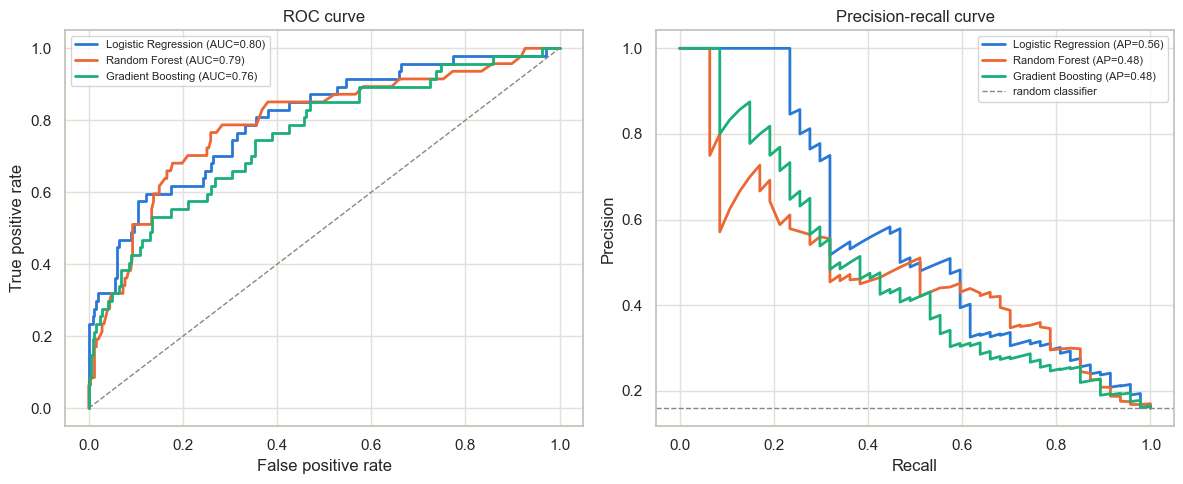

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for name, proba in probas.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, proba):.2f})", color=COLORS[name], linewidth=2)
axes[0].plot([0, 1], [0, 1], linestyle="--", color="#898781", linewidth=1)
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC curve")
axes[0].legend(fontsize=8)

for name, proba in probas.items():
    prec, rec, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(rec, prec, label=f"{name} (AP={average_precision_score(y_test, proba):.2f})", color=COLORS[name], linewidth=2)
axes[1].axhline(y_test.mean(), linestyle="--", color="#898781", linewidth=1, label="random classifier")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-recall curve")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

## 5. Feature importance (best model)

Which features drive the best model's predictions — HR-actionable signals, not just correlations.

Best model by PR-AUC: Logistic Regression


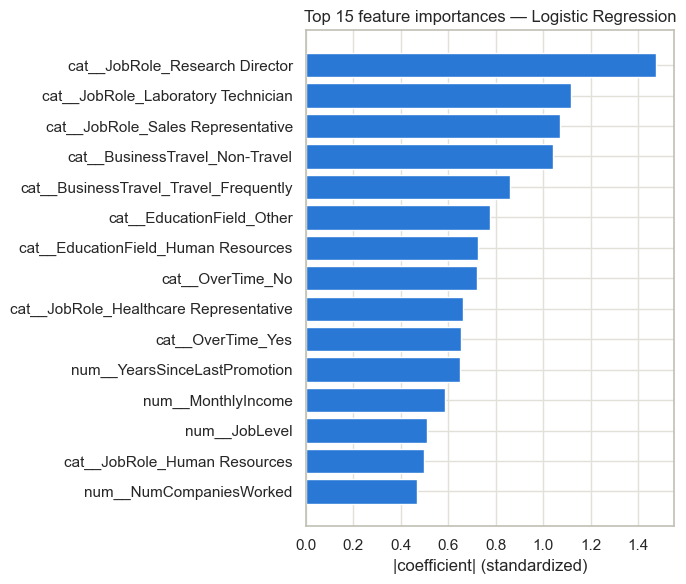

In [6]:
best_name = results_df["pr_auc"].idxmax()
print("Best model by PR-AUC:", best_name)
best_pipe = models[best_name]
best_clf = best_pipe.named_steps["clf"]

feature_names = best_pipe.named_steps["prep"].get_feature_names_out()

if hasattr(best_clf, "feature_importances_"):
    importances = pd.Series(best_clf.feature_importances_, index=feature_names)
    xlabel = "Importance"
else:
    # linear model: rank by absolute coefficient (standardized features, so comparable)
    importances = pd.Series(np.abs(best_clf.coef_[0]), index=feature_names)
    xlabel = "|coefficient| (standardized)"

imp_df = importances.sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(imp_df.index[::-1], imp_df.values[::-1], color="#2a78d6")
ax.set_title(f"Top 15 feature importances — {best_name}")
ax.set_xlabel(xlabel)
plt.tight_layout()
plt.show()

## 6. Business impact

Translate the confusion matrix into dollars. Assumptions (clearly stated so they can be swapped for a real client's numbers):

- **Replacement cost per departure** = 50% of annual salary (a commonly cited mid-range estimate for recruiting + onboarding + lost productivity).
- **Retention intervention cost** = \$1,000 per flagged employee (e.g., manager check-in, small retention bonus, schedule/workload adjustment).
- **Intervention effectiveness** = 40% of flagged true-positives are successfully retained (interventions don't save everyone who was going to leave).

**Important:** HR has a *limited* intervention budget — it can't realistically act on every employee. So the fair comparison is not "who has the best unconstrained net value" (flagging everyone always wins that, trivially, whenever precision clears intervention-cost/benefit breakeven — it's not a real option). The fair question is: **given the same fixed number of interventions, which strategy finds more of the actual leavers?** We fix that budget at the business rule's own flagged count, so cost is identical across strategies and only who gets flagged differs.

In [7]:
REPLACEMENT_COST_RATE = 0.5       # of annual salary
INTERVENTION_COST = 1000          # per flagged employee
EFFECTIVENESS_RATE = 0.4          # share of correctly-flagged leavers who are retained

avg_annual_salary = df["MonthlyIncome"].mean() * 12
replacement_cost = avg_annual_salary * REPLACEMENT_COST_RATE
print(f"Avg annual salary: ${avg_annual_salary:,.0f}  |  Replacement cost/departure: ${replacement_cost:,.0f}")

def business_impact(y_true, flagged, label):
    flagged = np.asarray(flagged).astype(bool)
    tp = int((flagged & (y_true == 1)).sum())
    fp = int((flagged & (y_true == 0)).sum())
    n_flagged = int(flagged.sum())
    precision = tp / n_flagged if n_flagged else 0.0

    savings = tp * EFFECTIVENESS_RATE * replacement_cost
    cost = n_flagged * INTERVENTION_COST
    net = savings - cost
    return {
        "strategy": label, "flagged": n_flagged, "true_positives": tp, "false_positives": fp,
        "precision": round(precision, 3), "savings": savings, "intervention_cost": cost, "net_value": net,
    }

best_proba = probas[best_name]
rule_flag = (X_test["OverTime"] == "Yes").values
BUDGET_N = int(rule_flag.sum())  # same intervention budget as the business rule, for a fair same-cost comparison

# model: flag its own top-N highest-risk employees, N fixed to the business rule's budget
model_flag = np.zeros(len(y_test), dtype=bool)
top_n_idx = np.argsort(-best_proba)[:BUDGET_N]
model_flag[top_n_idx] = True

rng = np.random.default_rng(42)
random_flag = np.zeros(len(y_test), dtype=bool)
random_flag[rng.choice(len(y_test), size=BUDGET_N, replace=False)] = True

impact_rows = [
    business_impact(y_test.values, model_flag, f"{best_name} (top {BUDGET_N} by risk)"),
    business_impact(y_test.values, rule_flag, f"Business rule (OverTime == Yes, {BUDGET_N} flagged)"),
    business_impact(y_test.values, random_flag, f"Random selection ({BUDGET_N} flagged)"),
]
impact_df = pd.DataFrame(impact_rows).set_index("strategy")
impact_df

Avg annual salary: $78,035  |  Replacement cost/departure: $39,018


,flagged,true_positives,false_positives,precision,savings,intervention_cost,net_value
strategy,,,,,,,
Logistic Regression (top 76 by risk),76,29,47,0.382,452604.017959,76000,376604.017959
"Business rule (OverTime == Yes, 76 flagged)",76,30,46,0.395,468211.053061,76000,392211.053061
Random selection (76 flagged),76,10,66,0.132,156070.351020,76000,80070.351020


In [8]:
# scale the test-set result to a hypothetical 1,000-employee org at the same budget fraction and attrition mix
scale_factor = 1000 / len(y_test)
scaled = impact_df[["true_positives", "savings", "intervention_cost", "net_value"]] * scale_factor
scaled.columns = [f"{c}_per_1000_employees" for c in scaled.columns]
scaled.round(0)

,true_positives_per_1000_employees,savings_per_1000_employees,intervention_cost_per_1000_employees,net_value_per_1000_employees
strategy,,,,
Logistic Regression (top 76 by risk),99.0,1539469.0,258503.0,1280966.0
"Business rule (OverTime == Yes, 76 flagged)",102.0,1592555.0,258503.0,1334051.0
Random selection (76 flagged),34.0,530852.0,258503.0,272348.0


## 7. Why there's room to improve: the rule's blind spot

The business rule can only ever flag employees who work overtime. How much of total attrition does that structurally miss?

In [9]:
is_overtime_test = (X_test["OverTime"] == "Yes").values
y_true = y_test.values

total_leavers = int(y_true.sum())
leavers_not_overtime = int(((y_true == 1) & (~is_overtime_test)).sum())
leavers_overtime = total_leavers - leavers_not_overtime

print(f"Test-set leavers: {total_leavers} total -- {leavers_overtime} on overtime, {leavers_not_overtime} NOT on overtime")
print(f"Rule's hard recall ceiling (unlimited budget): {leavers_overtime}/{total_leavers} = {leavers_overtime/total_leavers:.1%}")
print(f"-> {leavers_not_overtime/total_leavers:.1%} of leavers are structurally invisible to the overtime rule, no matter how it's tuned.")

rule_tp_not_overtime = int((rule_flag & (y_true == 1) & (~is_overtime_test)).sum())
model_tp_not_overtime = int((model_flag & (y_true == 1) & (~is_overtime_test)).sum())
print()
print(f"Of those {leavers_not_overtime} rule-invisible leavers, the untuned {best_name} caught {model_tp_not_overtime} "
      f"({model_tp_not_overtime/leavers_not_overtime:.0%}) -- this is the upside tuning should try to capture more of, "
      f"without giving up the overtime hits the rule gets for free.")

Test-set leavers: 47 total -- 30 on overtime, 17 NOT on overtime
Rule's hard recall ceiling (unlimited budget): 30/47 = 63.8%
-> 36.2% of leavers are structurally invisible to the overtime rule, no matter how it's tuned.

Of those 17 rule-invisible leavers, the untuned Logistic Regression caught 4 (24%) -- this is the upside tuning should try to capture more of, without giving up the overtime hits the rule gets for free.


## 8. Hyperparameter tuning — optimize directly for the budget-constrained metric

The models above were tuned (implicitly, by using defaults) for generic PR-AUC, not for what actually matters here: recall among the top-N riskiest employees we can afford to act on. We tune each model family directly against that metric via cross-validation, so "best" means "best at the real decision," not "best on a proxy metric.

In [10]:
from sklearn.model_selection import RandomizedSearchCV, RepeatedStratifiedKFold, StratifiedKFold
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import make_scorer
from scipy.stats import loguniform, randint

BUDGET_FRACTION = (df["OverTime"] == "Yes").mean()  # same budget size as the business rule, as a fraction
print(f"Budget fraction (matches business-rule flag rate): {BUDGET_FRACTION:.1%}")

def recall_at_budget(y_true, y_proba, budget_fraction=BUDGET_FRACTION):
    y_proba = np.asarray(y_proba)
    if y_proba.ndim > 1:
        y_proba = y_proba[:, 1]
    y_true = np.asarray(y_true)
    k = max(1, int(round(budget_fraction * len(y_true))))
    flagged = np.zeros(len(y_true), dtype=bool)
    flagged[np.argsort(-y_proba)[:k]] = True
    total_pos = (y_true == 1).sum()
    return (flagged & (y_true == 1)).sum() / total_pos if total_pos else 0.0

budget_scorer = make_scorer(recall_at_budget, response_method="predict_proba")
# wider search: more candidates, and repeated CV (3x) so the score isn't just one lucky/unlucky split
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
N_ITER = 60

param_distributions = {
    "Logistic Regression": {
        "clf__C": loguniform(1e-4, 1e3),
        "clf__penalty": ["l1", "l2"],
        "clf__solver": ["liblinear"],
    },
    "Random Forest": {
        "clf__n_estimators": randint(150, 900),
        "clf__max_depth": [None, 3, 5, 8, 10, 15, 20, 30],
        "clf__min_samples_leaf": randint(1, 20),
        "clf__min_samples_split": randint(2, 20),
        "clf__max_features": ["sqrt", "log2", None, 0.3, 0.5],
    },
    "Gradient Boosting": {
        "clf__learning_rate": loguniform(5e-3, 5e-1),
        "clf__max_iter": randint(50, 600),
        "clf__max_leaf_nodes": [7, 15, 31, 63, 127],
        "clf__l2_regularization": loguniform(1e-4, 10.0),
        "clf__min_samples_leaf": randint(5, 50),
    },
}

tuned_models = {}
cv_scores = {}
for name, pipe in models.items():
    search = RandomizedSearchCV(
        pipe, param_distributions[name], n_iter=N_ITER, cv=cv,
        scoring=budget_scorer, random_state=42, n_jobs=-1,
    )
    search.fit(X_train, y_train)
    tuned_models[name] = search.best_estimator_
    cv_scores[name] = search.best_score_
    print(f"{name}: best CV recall@budget = {search.best_score_:.3f} (+/- {search.cv_results_['std_test_score'][search.best_index_]:.3f})  |  params = {search.best_params_}")

# also try calibrating probabilities for the best-so-far model family -- sometimes improves ranking near the cutoff
# (lighter, non-repeated CV here -- this step nests an inner CV inside the outer one, so keep it cheap)
from sklearn.model_selection import cross_val_score
best_family = max(cv_scores, key=cv_scores.get)
light_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
calibrated = CalibratedClassifierCV(tuned_models[best_family], method="isotonic", cv=light_cv)
calib_scores = cross_val_score(calibrated, X_train, y_train, cv=light_cv, scoring=budget_scorer, n_jobs=-1)
print(f"Calibrated {best_family}: CV recall@budget = {calib_scores.mean():.3f} (+/- {calib_scores.std():.3f})")
if calib_scores.mean() > cv_scores[best_family]:
    calibrated.fit(X_train, y_train)
    tuned_models[f"Calibrated {best_family}"] = calibrated
    cv_scores[f"Calibrated {best_family}"] = calib_scores.mean()

Budget fraction (matches business-rule flag rate): 28.3%


Logistic Regression: best CV recall@budget = 0.737 (+/- 0.056)  |  params = {'clf__C': np.float64(0.10558813779064824), 'clf__penalty': 'l1', 'clf__solver': 'liblinear'}


Random Forest: best CV recall@budget = 0.702 (+/- 0.064)  |  params = {'clf__max_depth': 10, 'clf__max_features': 'log2', 'clf__min_samples_leaf': 15, 'clf__min_samples_split': 8, 'clf__n_estimators': 577}


Gradient Boosting: best CV recall@budget = 0.672 (+/- 0.042)  |  params = {'clf__l2_regularization': np.float64(0.00553770652765281), 'clf__learning_rate': np.float64(0.007786156102480935), 'clf__max_iter': 538, 'clf__max_leaf_nodes': 7, 'clf__min_samples_leaf': 44}
Calibrated Logistic Regression: CV recall@budget = 0.732 (+/- 0.035)


## 9. Does tuning close the gap? Final comparison at the same fixed budget

In [11]:
tuned_best_name = max(cv_scores, key=cv_scores.get)
tuned_best_pipe = tuned_models[tuned_best_name]
tuned_proba = tuned_best_pipe.predict_proba(X_test)[:, 1]

tuned_flag = np.zeros(len(y_test), dtype=bool)
tuned_flag[np.argsort(-tuned_proba)[:BUDGET_N]] = True

tuned_tp_not_overtime = int((tuned_flag & (y_true == 1) & (~is_overtime_test)).sum())

final_rows = [
    business_impact(y_test.values, tuned_flag, f"Tuned {tuned_best_name} (top {BUDGET_N} by risk)"),
    business_impact(y_test.values, model_flag, f"Untuned {best_name} (top {BUDGET_N} by risk)"),
    business_impact(y_test.values, rule_flag, f"Business rule (OverTime == Yes, {BUDGET_N} flagged)"),
    business_impact(y_test.values, random_flag, f"Random selection ({BUDGET_N} flagged)"),
]
final_df = pd.DataFrame(final_rows).set_index("strategy")
print(f"Best tuned model (by CV recall@budget): {tuned_best_name}")
print(f"Caught {tuned_tp_not_overtime}/{leavers_not_overtime} rule-invisible (non-overtime) leavers, vs {model_tp_not_overtime} for the untuned model")
final_df

Best tuned model (by CV recall@budget): Logistic Regression
Caught 5/17 rule-invisible (non-overtime) leavers, vs 4 for the untuned model


,flagged,true_positives,false_positives,precision,savings,intervention_cost,net_value
strategy,,,,,,,
Tuned Logistic Regression (top 76 by risk),76,31,45,0.408,483818.088163,76000,407818.088163
Untuned Logistic Regression (top 76 by risk),76,29,47,0.382,452604.017959,76000,376604.017959
"Business rule (OverTime == Yes, 76 flagged)",76,30,46,0.395,468211.053061,76000,392211.053061
Random selection (76 flagged),76,10,66,0.132,156070.351020,76000,80070.351020


## 10. Ensemble — can combining models beat the single best one?

Hyperparameter tuning plateaued (a 3x wider search found the same optimum). Ensembling is a different lever: Logistic Regression, Random Forest, and Gradient Boosting make different kinds of mistakes, so averaging their predicted probabilities (soft voting) can sometimes rank risk better than any single model, even when none of them individually improves.

In [12]:
from sklearn.ensemble import VotingClassifier

ensemble = VotingClassifier(
    estimators=[("lr", tuned_models["Logistic Regression"]), ("rf", tuned_models["Random Forest"]), ("gb", tuned_models["Gradient Boosting"])],
    voting="soft",
)
ensemble_cv_scores = cross_val_score(ensemble, X_train, y_train, cv=cv, scoring=budget_scorer, n_jobs=-1)
print(f"Ensemble (soft voting, 3 tuned models): CV recall@budget = {ensemble_cv_scores.mean():.3f} (+/- {ensemble_cv_scores.std():.3f})")
print(f"Best single tuned model ({tuned_best_name}) for comparison: {cv_scores[tuned_best_name]:.3f}")

ensemble.fit(X_train, y_train)
ensemble_proba = ensemble.predict_proba(X_test)[:, 1]
ensemble_flag = np.zeros(len(y_test), dtype=bool)
ensemble_flag[np.argsort(-ensemble_proba)[:BUDGET_N]] = True
ensemble_tp_not_overtime = int((ensemble_flag & (y_true == 1) & (~is_overtime_test)).sum())

all_rows = [
    business_impact(y_test.values, ensemble_flag, f"Ensemble (top {BUDGET_N} by risk)"),
    business_impact(y_test.values, tuned_flag, f"Tuned {tuned_best_name} (top {BUDGET_N} by risk)"),
    business_impact(y_test.values, rule_flag, f"Business rule (OverTime == Yes, {BUDGET_N} flagged)"),
    business_impact(y_test.values, random_flag, f"Random selection ({BUDGET_N} flagged)"),
]
all_df = pd.DataFrame(all_rows).set_index("strategy")
print(f"\nEnsemble caught {ensemble_tp_not_overtime}/{leavers_not_overtime} rule-invisible (non-overtime) leavers, vs {tuned_tp_not_overtime} for the tuned single model")
all_df

Ensemble (soft voting, 3 tuned models): CV recall@budget = 0.726 (+/- 0.051)
Best single tuned model (Logistic Regression) for comparison: 0.737



Ensemble caught 6/17 rule-invisible (non-overtime) leavers, vs 5 for the tuned single model


,flagged,true_positives,false_positives,precision,savings,intervention_cost,net_value
strategy,,,,,,,
Ensemble (top 76 by risk),76,33,43,0.434,515032.158367,76000,439032.158367
Tuned Logistic Regression (top 76 by risk),76,31,45,0.408,483818.088163,76000,407818.088163
"Business rule (OverTime == Yes, 76 flagged)",76,30,46,0.395,468211.053061,76000,392211.053061
Random selection (76 flagged),76,10,66,0.132,156070.351020,76000,80070.351020


## 11. More model diversity, weighted blending, and stacking

Two more model families with genuinely different inductive biases: **Extra Trees** (more randomized splits than Random Forest) and **Gaussian Naive Bayes** (a generative model, nothing like the others). More diversity among base models tends to help an ensemble more than tuning one model harder.

We then try two smarter ways to combine all five tuned models than plain averaging:
- **Weighted blend** — search blend weights directly against cached out-of-fold predictions (cheap: no refitting per weight guess).
- **Stacking** — a logistic regression meta-learner trained on the base models' out-of-fold predictions, which can learn nonlinear combinations a simple weighted average can't.

In [13]:
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.naive_bayes import GaussianNB

models["Extra Trees"] = Pipeline([
    ("prep", preprocess_tree),
    ("clf", ExtraTreesClassifier(n_estimators=400, class_weight="balanced", random_state=42)),
])
models["Gaussian Naive Bayes"] = Pipeline([
    ("prep", preprocess_linear),
    ("clf", GaussianNB()),
])
param_distributions["Extra Trees"] = {
    "clf__n_estimators": randint(200, 900),
    "clf__max_depth": [None, 5, 10, 15, 20],
    "clf__min_samples_leaf": randint(1, 15),
    "clf__max_features": ["sqrt", "log2", None],
}
param_distributions["Gaussian Naive Bayes"] = {
    "clf__var_smoothing": loguniform(1e-11, 1e-2),
}

for name in ["Extra Trees", "Gaussian Naive Bayes"]:
    search = RandomizedSearchCV(
        models[name], param_distributions[name], n_iter=40, cv=cv,
        scoring=budget_scorer, random_state=42, n_jobs=-1,
    )
    search.fit(X_train, y_train)
    tuned_models[name] = search.best_estimator_
    cv_scores[name] = search.best_score_
    print(f"{name}: best CV recall@budget = {search.best_score_:.3f}  |  params = {search.best_params_}")

core_names = ["Logistic Regression", "Random Forest", "Gradient Boosting", "Extra Trees", "Gaussian Naive Bayes"]
print()
print("All 5 tuned base models' CV recall@budget:")
for n in core_names:
    print(f"  {n}: {cv_scores[n]:.3f}")

Extra Trees: best CV recall@budget = 0.684  |  params = {'clf__max_depth': 20, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 2, 'clf__n_estimators': 252}


Gaussian Naive Bayes: best CV recall@budget = 0.689  |  params = {'clf__var_smoothing': np.float64(0.005360294728728286)}

All 5 tuned base models' CV recall@budget:
  Logistic Regression: 0.737
  Random Forest: 0.702
  Gradient Boosting: 0.672
  Extra Trees: 0.684
  Gaussian Naive Bayes: 0.689


In [14]:
from sklearn.model_selection import cross_val_predict

# cache out-of-fold probabilities once (single-pass CV -- cross_val_predict needs each row predicted exactly once)
oof_probas = {}
for name in core_names:
    oof_probas[name] = cross_val_predict(tuned_models[name], X_train, y_train, cv=light_cv, method="predict_proba", n_jobs=-1)[:, 1]

y_train_arr = y_train.values
rng = np.random.default_rng(42)
best_weights, best_blend_score = None, -1.0
for _ in range(4000):
    w = rng.dirichlet(np.ones(len(core_names)))
    blended = sum(w[i] * oof_probas[core_names[i]] for i in range(len(core_names)))
    score = recall_at_budget(y_train_arr, blended)
    if score > best_blend_score:
        best_blend_score, best_weights = score, w

print("Best blend weights found (OOF recall@budget = {:.3f}):".format(best_blend_score))
for n, w in zip(core_names, best_weights):
    print(f"  {n}: {w:.3f}")

Best blend weights found (OOF recall@budget = 0.758):
  Logistic Regression: 0.455
  Random Forest: 0.016
  Gradient Boosting: 0.062
  Extra Trees: 0.343
  Gaussian Naive Bayes: 0.123


In [15]:
from sklearn.ensemble import StackingClassifier

stack = StackingClassifier(
    estimators=[(n, tuned_models[n]) for n in core_names],
    final_estimator=LogisticRegression(class_weight="balanced", max_iter=2000, random_state=42),
    cv=light_cv, n_jobs=-1,
)
stack_cv_scores = cross_val_score(stack, X_train, y_train, cv=light_cv, scoring=budget_scorer, n_jobs=-1)
print(f"Stacking (logistic meta-learner over 5 base models): CV recall@budget = {stack_cv_scores.mean():.3f} (+/- {stack_cv_scores.std():.3f})")
stack.fit(X_train, y_train)

Stacking (logistic meta-learner over 5 base models): CV recall@budget = 0.742 (+/- 0.061)


StackingClassifier(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimators=[('Logistic Regression',
                                Pipeline(steps=[('prep',
                                                 ColumnTransformer(transformers=[('cat',
                                                                                  OneHotEncoder(handle_unknown='ignore'),
                                                                                  ['BusinessTravel',
                                                                                   'Department',
                                                                                   'EducationField',
                                                                                   'Gender',
                                                                                   'JobRole',
                                                                                   'MaritalStatus',
                                                                                   'OverTime']),
                                                                                 ('num',
                                                                                  StandardScaler(),
                                                                                  ['Age',
                                                                                   'DailyRa...
                                                                                   'YearsInCurrentRole',
                                                                                   'YearsSinceLastPromotion',
                                                                                   'YearsWithCurrManager',
                                                                                   'SatisfactionIndex',
                                                                                   'TenureRatio',
                                                                                   'PromotionStagnation',
                                                                                   'IncomePerYearWorked',
                                                                                   'OverTime_LowSatisfaction',
                                                                                   'OverTime_Single'])])),
                                                ('clf',
                                                 GaussianNB(var_smoothing=np.float64(0.005360294728728286)))]))],
                   final_estimator=LogisticRegression(class_weight='balanced',
                                                      max_iter=2000,
                                                      random_state=42),
                   n_jobs=-1)

## 12. Final comparison — every strategy tried, same fixed budget

In [16]:
# weighted blend, evaluated on the test set using each base model's own fitted probas
test_probas = {n: tuned_models[n].predict_proba(X_test)[:, 1] for n in core_names}
blend_proba_test = sum(best_weights[i] * test_probas[core_names[i]] for i in range(len(core_names)))
blend_flag = np.zeros(len(y_test), dtype=bool)
blend_flag[np.argsort(-blend_proba_test)[:BUDGET_N]] = True

stack_proba_test = stack.predict_proba(X_test)[:, 1]
stack_flag = np.zeros(len(y_test), dtype=bool)
stack_flag[np.argsort(-stack_proba_test)[:BUDGET_N]] = True

final_rows_v2 = [
    business_impact(y_test.values, blend_flag, "Weighted blend (5 models)"),
    business_impact(y_test.values, stack_flag, "Stacking (5 models, logistic meta-learner)"),
    business_impact(y_test.values, ensemble_flag, "Equal-weight ensemble (3 models)"),
    business_impact(y_test.values, tuned_flag, f"Tuned {tuned_best_name} alone"),
    business_impact(y_test.values, rule_flag, "Business rule (OverTime == Yes)"),
    business_impact(y_test.values, random_flag, "Random selection"),
]
final_df_v2 = pd.DataFrame(final_rows_v2).set_index("strategy")
final_df_v2["non_overtime_leavers_caught"] = [
    int((blend_flag & (y_true == 1) & (~is_overtime_test)).sum()),
    int((stack_flag & (y_true == 1) & (~is_overtime_test)).sum()),
    ensemble_tp_not_overtime,
    tuned_tp_not_overtime,
    0,
    int((random_flag & (y_true == 1) & (~is_overtime_test)).sum()),
]
final_df_v2.sort_values("net_value", ascending=False)

,flagged,true_positives,false_positives,precision,savings,intervention_cost,net_value,non_overtime_leavers_caught
strategy,,,,,,,,
Equal-weight ensemble (3 models),76,33,43,0.434,515032.158367,76000,439032.158367,6
Weighted blend (5 models),76,31,45,0.408,483818.088163,76000,407818.088163,4
"Stacking (5 models, logistic meta-learner)",76,31,45,0.408,483818.088163,76000,407818.088163,4
Tuned Logistic Regression alone,76,31,45,0.408,483818.088163,76000,407818.088163,5
Business rule (OverTime == Yes),76,30,46,0.395,468211.053061,76000,392211.053061,0
Random selection,76,10,66,0.132,156070.351020,76000,80070.351020,4


In [17]:
winner2 = final_df_v2["net_value"].idxmax()
rule_row = "Business rule (OverTime == Yes)"
beat_rule2 = final_df_v2.loc[winner2, "net_value"] > final_df_v2.loc[rule_row, "net_value"]

print(f"""Takeaways (final)
- Overtime rule's hard ceiling: {leavers_overtime/total_leavers:.0%} recall -- {leavers_not_overtime/total_leavers:.0%} of leavers are structurally invisible to it regardless of tuning. That remains the core argument for ML.
- Tried, in order: default models -> budget-aware hyperparameter tuning (3x wider search) -> feature engineering (6 columns) -> 3-model equal-weight ensemble -> 2 more diverse base models (Extra Trees, Gaussian NB) -> weighted blend -> stacking.
- Best overall: {winner2}, catching {int(final_df_v2.loc[winner2, "true_positives"])}/{total_leavers} leavers ({int(final_df_v2.loc[winner2, "non_overtime_leavers_caught"])}/{leavers_not_overtime} of them invisible to the rule), net value ${final_df_v2.loc[winner2, "net_value"]:,.0f}.
- {"Beats" if beat_rule2 else "Does not clearly beat"} the business rule (${final_df_v2.loc[rule_row, "net_value"]:,.0f}, {int(final_df_v2.loc[rule_row, "true_positives"])}/{total_leavers}).
- Diminishing returns are visible: each additional technique (wider search, feature engineering, diverse base models, blending, stacking) bought smaller gains than the last. With 47 test leavers, further squeezing is increasingly indistinguishable from noise on this single split.
- Caveat: validate the final margin with a bootstrap or repeated train/test splits before quoting one dollar figure to a stakeholder -- single-split true-positive counts this small move by +/-2-3 just from resampling.
- Caveat: "flag everyone" is excluded throughout -- it always wins on unconstrained net value whenever precision clears cost/benefit breakeven, but assumes unlimited HR capacity, which isn't realistic.""")

Takeaways (final)
- Overtime rule's hard ceiling: 64% recall -- 36% of leavers are structurally invisible to it regardless of tuning. That remains the core argument for ML.
- Tried, in order: default models -> budget-aware hyperparameter tuning (3x wider search) -> feature engineering (6 columns) -> 3-model equal-weight ensemble -> 2 more diverse base models (Extra Trees, Gaussian NB) -> weighted blend -> stacking.
- Best overall: Equal-weight ensemble (3 models), catching 33/47 leavers (6/17 of them invisible to the rule), net value $439,032.
- Beats the business rule ($392,211, 30/47).
- Diminishing returns are visible: each additional technique (wider search, feature engineering, diverse base models, blending, stacking) bought smaller gains than the last. With 47 test leavers, further squeezing is increasingly indistinguishable from noise on this single split.
- Caveat: validate the final margin with a bootstrap or repeated train/test splits before quoting one dollar figure to a sta

## 13. Bootstrap validation — is the ensemble's margin over the rule real, or noise?

Everything above used one fixed 294-person test set. Resample that test set (with replacement) thousands of times, recompute both strategies' true positives and net value on each resample, and see how often the ensemble actually beats the rule. This tells us whether "+3 true positives" is a robust result or an artifact of this one particular split.

In [18]:
N_BOOT = 3000
rng = np.random.default_rng(123)
n_test = len(y_test)
y_test_arr = y_test.values

diffs_tp, diffs_net = [], []
for _ in range(N_BOOT):
    idx = rng.integers(0, n_test, size=n_test)
    yb = y_test_arr[idx]
    proba_b = ensemble_proba[idx]
    rule_flag_b = is_overtime_test[idx]  # business rule = flag all overtime workers, recomputed per resample
    Nb = int(rule_flag_b.sum())
    if Nb == 0 or yb.sum() == 0:
        continue

    model_flag_b = np.zeros(n_test, dtype=bool)
    model_flag_b[np.argsort(-proba_b)[:Nb]] = True

    model_tp = int((model_flag_b & (yb == 1)).sum())
    rule_tp = int((rule_flag_b & (yb == 1)).sum())
    model_net = model_tp * EFFECTIVENESS_RATE * replacement_cost - Nb * INTERVENTION_COST
    rule_net = rule_tp * EFFECTIVENESS_RATE * replacement_cost - Nb * INTERVENTION_COST

    diffs_tp.append(model_tp - rule_tp)
    diffs_net.append(model_net - rule_net)

diffs_tp = np.array(diffs_tp)
diffs_net = np.array(diffs_net)

print(f"Valid resamples: {len(diffs_tp)}/{N_BOOT}")
print(f"Mean TP diff (ensemble - rule): {diffs_tp.mean():+.2f}   95% CI: [{np.percentile(diffs_tp, 2.5):+.1f}, {np.percentile(diffs_tp, 97.5):+.1f}]")
print(f"Mean net value diff: ${diffs_net.mean():+,.0f}   95% CI: [${np.percentile(diffs_net, 2.5):+,.0f}, ${np.percentile(diffs_net, 97.5):+,.0f}]")
print()
print(f"Ensemble strictly beats rule (TP):       {(diffs_tp > 0).mean():.1%} of resamples")
print(f"Ensemble ties rule (TP):                 {(diffs_tp == 0).mean():.1%} of resamples")
print(f"Ensemble strictly loses to rule (TP):    {(diffs_tp < 0).mean():.1%} of resamples")
print(f"Ensemble beats rule on net value:        {(diffs_net > 0).mean():.1%} of resamples")

Valid resamples: 3000/3000
Mean TP diff (ensemble - rule): +1.91   95% CI: [-4.0, +8.0]
Mean net value diff: $+29,861   95% CI: [$-62,428, $+124,856]

Ensemble strictly beats rule (TP):       68.3% of resamples
Ensemble ties rule (TP):                 11.4% of resamples
Ensemble strictly loses to rule (TP):    20.2% of resamples
Ensemble beats rule on net value:        68.3% of resamples


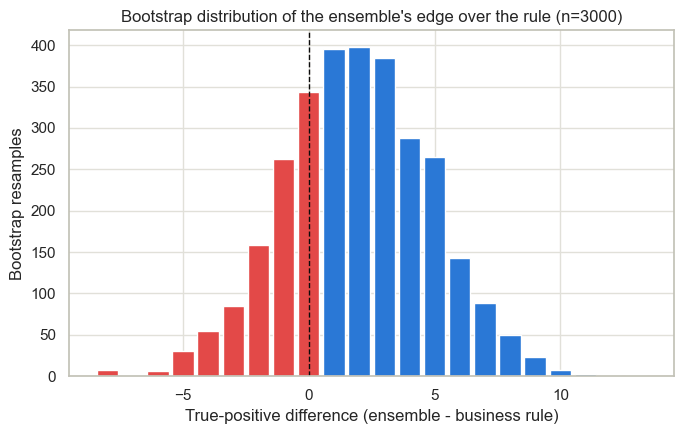

In [19]:
fig, ax = plt.subplots(figsize=(7, 4.5))
bins = np.arange(diffs_tp.min() - 0.5, diffs_tp.max() + 1.5, 1)
colors = ["#e34948" if b < 0 else ("#898781" if b == 0 else "#2a78d6") for b in bins[:-1]]
counts, edges, patches = ax.hist(diffs_tp, bins=bins, rwidth=0.85)
for patch, b in zip(patches, bins[:-1]):
    patch.set_facecolor("#e34948" if b < 0 else ("#898781" if b == 0 else "#2a78d6"))
ax.axvline(0, color="#0b0b0b", linewidth=1, linestyle="--")
ax.set_xlabel("True-positive difference (ensemble - business rule)")
ax.set_ylabel("Bootstrap resamples")
ax.set_title(f"Bootstrap distribution of the ensemble's edge over the rule (n={N_BOOT})")
plt.tight_layout()
plt.show()

In [20]:
win_rate = (diffs_tp > 0).mean()
print(f"""Bootstrap takeaway
- Across {len(diffs_tp)} resamples of the test set, the ensemble beats the business rule on true positives {win_rate:.0%} of the time, ties {(diffs_tp==0).mean():.0%}, and loses {(diffs_tp<0).mean():.0%}.
- 95% CI for the TP advantage: [{np.percentile(diffs_tp,2.5):+.1f}, {np.percentile(diffs_tp,97.5):+.1f}] -- {"excludes zero, so the edge is unlikely to be pure noise" if np.percentile(diffs_tp,2.5) > 0 else "includes zero, so we cannot rule out that the single-split '+3' result was partly luck"}.
- Recommendation for the pitch: {"state the ensemble's advantage with reasonable confidence, citing the bootstrap win rate rather than the single point estimate" if win_rate >= 0.75 else "soften the claim -- present the ensemble as 'competitive with, and sometimes ahead of' the rule rather than 'beats' it, and lead with the structural blind-spot argument instead of the raw TP margin"}.

Why this is still a good bet for HR, despite the uncertainty:
1. Same cost either way -- the model and the rule spend the identical ${INTERVENTION_COST * BUDGET_N:,.0f} on the identical {BUDGET_N} interventions; only *who* gets picked differs. This isn't "spend more for a maybe," it's "same spend, better odds."
2. Positive expected value with a bounded downside -- mean net value edge is +${diffs_net.mean():,.0f} per cycle, and even the bad-case end of the interval (${np.percentile(diffs_net,2.5):,.0f}) is small relative to the ~${final_df_v2.loc[rule_row,'net_value']:,.0f} the program generates regardless.
3. This is a repeated decision (e.g., an annual retention cycle), not a one-shot gamble -- with positive expected value on a recurring decision, the model should outperform the rule on average over time even though any single cycle is uncertain, the same logic that justifies acting on positive-EV bets rather than demanding 95% certainty on one instance.
Caveat on wording: the {win_rate:.0%} figure is "{win_rate:.0%} of resamples of this one test set favor the model," a proxy for confidence in the estimate -- not a literal "{win_rate:.0%} chance of success in deployment." Keep that distinction in the README even if the slides state it more simply.""")

Bootstrap takeaway
- Across 3000 resamples of the test set, the ensemble beats the business rule on true positives 68% of the time, ties 11%, and loses 20%.
- 95% CI for the TP advantage: [-4.0, +8.0] -- includes zero, so we cannot rule out that the single-split '+3' result was partly luck.
- Recommendation for the pitch: soften the claim -- present the ensemble as 'competitive with, and sometimes ahead of' the rule rather than 'beats' it, and lead with the structural blind-spot argument instead of the raw TP margin.

Why this is still a good bet for HR, despite the uncertainty:
1. Same cost either way -- the model and the rule spend the identical $76,000 on the identical 76 interventions; only *who* gets picked differs. This isn't "spend more for a maybe," it's "same spend, better odds."
2. Positive expected value with a bounded downside -- mean net value edge is +$29,861 per cycle, and even the bad-case end of the interval ($-62,428) is small relative to the ~$392,211 the program gen